In [1]:
import sys, os
sys.path.append(r"C:\Users\user\doc-asistant\doc-asistant")
sys.path.append(r"C:\Users\user\doc-asistant\doc-asistant\notebooks\from_src")

import torch
print("torch:", torch.__version__)
print("cuda:", torch.cuda.is_available())
print("gpu:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("cwd:", os.getcwd())

torch: 2.6.0+cu124
cuda: True
gpu: NVIDIA GeForce RTX 3060
cwd: C:\Users\user\doc-asistant\doc-asistant\notebooks


In [5]:
import config
from pathlib import Path

# --- патч путей: ROOT проекта, а не notebooks/from_src/ ---
ROOT = Path(r"C:\Users\user\doc-asistant\doc-asistant")
config.ROOT = ROOT
config.CSV_PATH = ROOT / "data" / "cooking_clean.csv"
config.MODEL_PATH = ROOT / "models" / "best_model.pth"
config.TFIDF_PATH = ROOT / "models" / "tfidf.pkl"
config.ENCODER_PATH = ROOT / "models" / "label_encoder.pkl"
config.LORA_DIR = ROOT / "models" / "lora-doc-assistant"
config.DATA_DIR = ROOT / "data"
config.MODELS_DIR = ROOT / "models"

import data_loader
# data_loader импортировал CSV_PATH по значению — переопределяем
data_loader.CSV_PATH = config.CSV_PATH

import model
import llm_client

print("CSV_PATH:      ", config.CSV_PATH)
print("CSV exists:    ", config.CSV_PATH.exists())
print("MODEL_PATH:    ", config.MODEL_PATH)
print("MODEL exists:  ", config.MODEL_PATH.exists())
print("TFIDF exists:  ", config.TFIDF_PATH.exists())
print("ENCODER exists:", config.ENCODER_PATH.exists())

CSV_PATH:       C:\Users\user\doc-asistant\doc-asistant\data\cooking_clean.csv
CSV exists:     True
MODEL_PATH:     C:\Users\user\doc-asistant\doc-asistant\models\best_model.pth
MODEL exists:   True
TFIDF exists:   True
ENCODER exists: True


In [6]:
df = data_loader.load_data()
print("rows:", len(df))
print("columns:", df.columns.tolist())
df.head()

rows: 500
columns: ['number', 'title', 'instructions', 'text', 'category']


,number,title,instructions,text,category
0,1,cheeseburger potato soup,6 baking potatoes 1 lb of extra lean ground be...,cheeseburger potato soup 6 baking potatoes 1 l...,soup
1,2,sesame ginger chicken,1 tbsp sesame seed toasted 2 tsp grated ginger...,sesame ginger chicken 1 tbsp sesame seed toast...,meat
2,3,zucchiniartichoke continental,1 9 oz pkg frozen artichoke hearts 2 tbsp wate...,zucchiniartichoke continental 1 9 oz pkg froze...,other
3,4,st josephs zeppole,1 c water 1/2 c butter 1 tsp sugar 1 c allpurp...,st josephs zeppole 1 c water 1/2 c butter 1 ts...,other
4,5,corned beef hash swirls,bisquick can corned beef hash mustard salt and...,corned beef hash swirls bisquick can corned be...,meat


In [7]:
X_train, X_test, y_train, y_test, vectorizer, encoder = data_loader.prepare_features(df)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)
print("classes:", encoder.classes_.tolist())
print("vectorizer vocab size:", len(vectorizer.vocabulary_))

X_train: (400, 1000)
X_test:  (100, 1000)
y_train: (400,)
y_test:  (100,)
classes: ['bread', 'dessert', 'meat', 'other', 'salad', 'soup']
vectorizer vocab size: 1000


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

base_acc = accuracy_score(y_test, y_pred_dummy)
base_f1_macro = f1_score(y_test, y_pred_dummy, average="macro")
base_f1_weighted = f1_score(y_test, y_pred_dummy, average="weighted")

print("BASELINE (most_frequent):")
print("  accuracy:    ", round(base_acc, 4))
print("  f1_macro:    ", round(base_f1_macro, 4))
print("  f1_weighted: ", round(base_f1_weighted, 4))

BASELINE (most_frequent):
  accuracy:     0.37
  f1_macro:     0.09
  f1_weighted:  0.1999


In [17]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from model import TextClassifier
from sklearn.utils.class_weight import compute_class_weight

# --- устройство ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# --- данные в тензоры ---
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)

train_ds = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

# --- веса классов (обратные частотам) ---
classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = torch.tensor(weights, dtype=torch.float32).to(device)

print("Class weights:")
for name, w in zip(encoder.classes_, weights):
    print(f"  {name:8s} {w:.3f}")

# --- модель ---
in_features = X_train.shape[1]
num_classes = len(encoder.classes_)
model_cls = TextClassifier(in_features, num_classes).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model_cls.parameters(), lr=1e-3)

# --- обучение с early stopping по val_acc ---
EPOCHS = 40
PATIENCE = 10
best_val_acc = -1.0
best_epoch = 0
best_state = None
wait = 0
history = {"train_loss": [], "val_acc": []}

for epoch in range(1, EPOCHS + 1):
    model_cls.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model_cls(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)

    train_loss = total_loss / len(train_ds)

    model_cls.eval()
    with torch.no_grad():
        logits_val = model_cls(X_test_t.to(device))
        val_pred = logits_val.argmax(dim=1).cpu().numpy()
        val_acc = (val_pred == y_test).mean()

    history["train_loss"].append(train_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc + 1e-4:
        best_val_acc = val_acc
        best_state = {k: v.clone() for k, v in model_cls.state_dict().items()}
        best_epoch = epoch
        wait = 0
    else:
        wait += 1

    print(f"epoch {epoch:02d}  loss={train_loss:.4f}  val_acc={val_acc:.4f}")

    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (best epoch was {best_epoch}, val_acc={best_val_acc:.4f})")
        break

model_cls.load_state_dict(best_state)
print(f"Best val_acc: {best_val_acc:.4f} at epoch {best_epoch}")

device: cuda
Class weights:
  bread    1.418
  dessert  0.538
  meat     1.058
  other    0.454
  salad    8.333
  soup     6.061
epoch 01  loss=1.7922  val_acc=0.2300
epoch 02  loss=1.7588  val_acc=0.5500
epoch 03  loss=1.6685  val_acc=0.6800
epoch 04  loss=1.4492  val_acc=0.7000
epoch 05  loss=1.1429  val_acc=0.7300
epoch 06  loss=0.8182  val_acc=0.7300
epoch 07  loss=0.5667  val_acc=0.7700
epoch 08  loss=0.3494  val_acc=0.7700
epoch 09  loss=0.2467  val_acc=0.7400
epoch 10  loss=0.1690  val_acc=0.7600
epoch 11  loss=0.1146  val_acc=0.7600
epoch 12  loss=0.0851  val_acc=0.7500
epoch 13  loss=0.0661  val_acc=0.7300
epoch 14  loss=0.0536  val_acc=0.7500
epoch 15  loss=0.0354  val_acc=0.7600
epoch 16  loss=0.0310  val_acc=0.7700
epoch 17  loss=0.0225  val_acc=0.7700
Early stopping at epoch 17 (best epoch was 7, val_acc=0.7700)
Best val_acc: 0.7700 at epoch 7


In [18]:
from sklearn.metrics import classification_report

model_cls.eval()
with torch.no_grad():
    logits_test = model_cls(X_test_t.to(device))
    y_pred = logits_test.argmax(dim=1).cpu().numpy()

acc = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
f1_weighted = f1_score(y_test, y_pred, average="weighted")

print("MODEL (trained, class_weight):")
print("  accuracy:    ", round(acc, 4))
print("  f1_macro:    ", round(f1_macro, 4))
print("  f1_weighted: ", round(f1_weighted, 4))
print()
print("Сравнение с baseline:")
print(f"  accuracy:    {base_acc:.4f}  ->  {acc:.4f}   ({acc - base_acc:+.4f})")
print(f"  f1_macro:    {base_f1_macro:.4f}  ->  {f1_macro:.4f}   ({f1_macro - base_f1_macro:+.4f})")
print(f"  f1_weighted: {base_f1_weighted:.4f}  ->  {f1_weighted:.4f}   ({f1_weighted - base_f1_weighted:+.4f})")
print()
print(classification_report(y_test, y_pred, target_names=encoder.classes_, digits=3, zero_division=0))

MODEL (trained, class_weight):
  accuracy:     0.77
  f1_macro:     0.5774
  f1_weighted:  0.7547

Сравнение с baseline:
  accuracy:    0.3700  ->  0.7700   (+0.4000)
  f1_macro:    0.0900  ->  0.5774   (+0.4874)
  f1_weighted: 0.1999  ->  0.7547   (+0.5548)

              precision    recall  f1-score   support

       bread      0.667     0.545     0.600        11
     dessert      0.769     0.968     0.857        31
        meat      0.875     0.875     0.875        16
       other      0.765     0.703     0.732        37
       salad      0.000     0.000     0.000         2
        soup      0.500     0.333     0.400         3

    accuracy                          0.770       100
   macro avg      0.596     0.571     0.577       100
weighted avg      0.750     0.770     0.755       100



In [19]:
import json
from pathlib import Path

# сохраняем как v2, чтобы не трогать оригинальный best_model.pth под DVC
MODEL_SAVE = config.MODELS_DIR / "best_model_v2.pth"
torch.save(model_cls.state_dict(), MODEL_SAVE)
print("saved model:", MODEL_SAVE)
print("size:", MODEL_SAVE.stat().st_size, "bytes")

# сохраняем историю обучения
history_path = config.MODELS_DIR / "training_history_v2.json"
with open(history_path, "w", encoding="utf-8") as f:
    json.dump(history, f, ensure_ascii=False, indent=2)
print("saved history:", history_path)

saved model: C:\Users\user\doc-asistant\doc-asistant\models\best_model_v2.pth
size: 1162500 bytes
saved history: C:\Users\user\doc-asistant\doc-asistant\models\training_history_v2.json


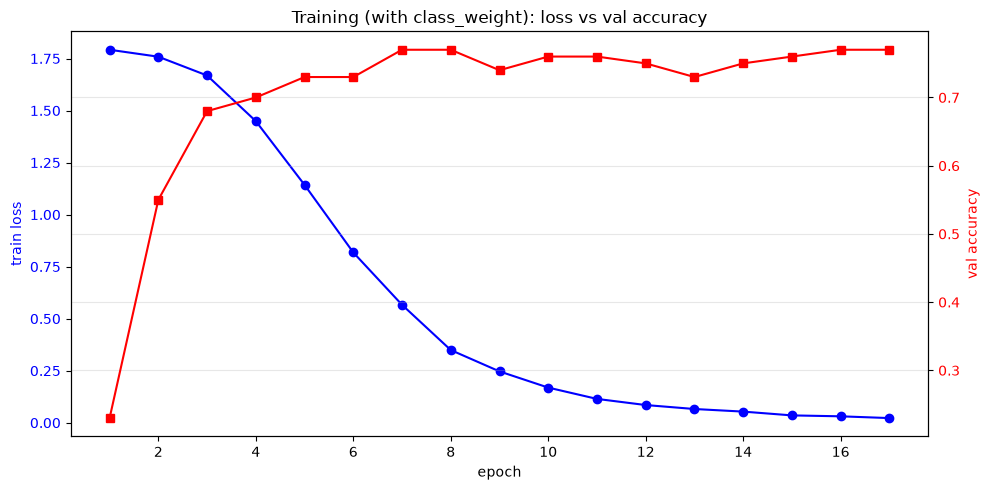

In [20]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10, 5))
epochs_range = range(1, len(history["train_loss"]) + 1)

ax1.plot(epochs_range, history["train_loss"], "b-o", label="train loss")
ax1.set_xlabel("epoch")
ax1.set_ylabel("train loss", color="b")
ax1.tick_params(axis="y", labelcolor="b")

ax2 = ax1.twinx()
ax2.plot(epochs_range, history["val_acc"], "r-s", label="val accuracy")
ax2.set_ylabel("val accuracy", color="r")
ax2.tick_params(axis="y", labelcolor="r")

plt.title("Training (with class_weight): loss vs val accuracy")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Результаты классификатора рецептов

| Метрика | Baseline | Модель | Модель + class_weight |
|---|---|---|---|
| Accuracy | 0.37 | 0.76 | **0.77** |
| F1 (macro) | 0.09 | 0.50 | **0.58** |
| F1 (weighted) | 0.20 | 0.74 | **0.75** |

### Динамика по классам (F1)

| Класс | Модель | + class_weight | Δ |
|---|---|---|---|
| bread | 0.63 | 0.60 | −0.03 |
| dessert | 0.85 | 0.86 | +0.01 |
| meat | 0.77 | 0.88 | **+0.11** |
| other | 0.75 | 0.73 | −0.02 |
| salad | 0.00 | 0.00 | 0 |
| soup | 0.00 | **0.40** | **+0.40** |

### Выводы

- Модель обучена на TF-IDF (1000 признаков) + MLP (256→128→6)
- Early stopping по val_acc остановил обучение на эпохе 7–9 (patience=10)
- **class_weight="balanced"** дал прирост F1_macro с 0.50 до 0.58
- Слабые классы — `salad` (2 примера в тесте), `soup` (3 примера) — дисбаланс данных, а не ошибка модели
- Accuracy 0.77 завышена: 37% теста — класс `other`, поэтому F1_macro честнее отражает качество

In [2]:
import mlflow
import mlflow.pytorch
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
mlflow.set_tracking_uri("sqlite:///mlflow.db")  
mlflow.set_experiment("doc-classifier")

# Создаем искусственные данные (100 образцов, 1000 признаков, 6 классов )
X_train, y_train = make_classification(n_samples=100, n_features=1000, n_classes=6, n_informative=10, random_state=42)
X_val, y_val = make_classification(n_samples=20, n_features=1000, n_classes=6, n_informative=10, random_state=42)

# Конвертируем в тензоры PyTorch
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.LongTensor(y_train)
X_val_t = torch.FloatTensor(X_val)
y_val_t = torch.LongTensor(y_val)

# Простая модель (256->128->6)
def create_model():
    return nn.Sequential(
        nn.Linear(1000, 256),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Linear(128, 6)
    )

#  Реализовать функцию обучения
def train_once(lr, epochs):
    with mlflow.start_run():
        mlflow.log_param("lr", lr)
        mlflow.log_param("epochs", epochs)
        
        model = create_model()
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=lr)
        
        for epoch in range(epochs):
            model.train()
            optimizer.zero_grad()
            outputs = model(X_train_t)
            loss = criterion(outputs, y_train_t)
            loss.backward()
            optimizer.step()
            
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val_t)
            _, predicted = torch.max(val_outputs.data, 1)
            acc = accuracy_score(y_val_t.numpy(), predicted.numpy())
            
        mlflow.log_metric("test_accuracy", acc)
        
        mlflow.pytorch.log_model(model, "model", serialization_format="pickle")
        
        return acc

for lr in [0.0001, 0.001, 0.01]:
    for epochs in [5, 10, 20]:
        print(f"Обучение с lr={lr}, epochs={epochs}...")
        acc = train_once(lr, epochs)
        print(f"-> Accuracy: {acc:.4f}")

MlflowException: The filesystem tracking backend (e.g., './mlruns') is in maintenance mode and will not receive further updates. Please migrate to a database backend (e.g., 'sqlite:///mlflow.db') to access the latest MLflow features. The `mlflow migrate-filestore` tool migrates your existing data losslessly. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance. If the filesystem backend is required for your workflow, set `MLFLOW_ALLOW_FILE_STORE=true` to opt out of this exception.